# Mejor modelo XGBoost con MLflow

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrena el mejor modelo XGBoost encontrado en `05_model_xgboost.ipynb`, calcula metricas de evaluacion y registra el experimento en MLflow.

In [34]:
# Importe los conjuntos de datos procesados y separe variables predictoras y objetivo
import pandas as pd
import numpy as np
import seaborn as sns
import json
import tempfile
import mlflow
import mlflow.xgboost
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
)
from xgboost import XGBClassifier

In [35]:
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]

In [36]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

feature_columns = [
    column
    for column in train_df.columns
    if column not in [TARGET_COLUMN, *ID_COLUMNS]
]
print(f"Columnas: {feature_columns}")

Columnas: ['EEG_Fpz-Cz__delta_power_abs', 'EEG_Fpz-Cz__delta_power_rel', 'EEG_Fpz-Cz__theta_power_abs', 'EEG_Fpz-Cz__theta_power_rel', 'EEG_Fpz-Cz__alpha_power_abs', 'EEG_Fpz-Cz__alpha_power_rel', 'EEG_Fpz-Cz__sigma_power_abs', 'EEG_Fpz-Cz__sigma_power_rel', 'EEG_Fpz-Cz__beta_power_abs', 'EEG_Fpz-Cz__beta_power_rel', 'EEG_Fpz-Cz__delta_alpha_ratio', 'EEG_Fpz-Cz__theta_alpha_ratio', 'EEG_Fpz-Cz__sef95', 'EEG_Fpz-Cz__spectral_entropy']


In [37]:
test_df[TARGET_COLUMN].unique()

array([0, 2, 3, 1, 4])

In [38]:
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df[TARGET_COLUMN]
y_test = test_df[TARGET_COLUMN]

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print(f"Numero de features: {len(feature_columns)}")
print(f"Clases: {test_df[TARGET_COLUMN].unique()}")

Train shape: (150272, 14)
Test shape: (45207, 14)
Numero de features: 14
Clases: [0 2 3 1 4]


In [39]:
train_df.columns

Index(['EEG_Fpz-Cz__delta_power_abs', 'EEG_Fpz-Cz__delta_power_rel',
       'EEG_Fpz-Cz__theta_power_abs', 'EEG_Fpz-Cz__theta_power_rel',
       'EEG_Fpz-Cz__alpha_power_abs', 'EEG_Fpz-Cz__alpha_power_rel',
       'EEG_Fpz-Cz__sigma_power_abs', 'EEG_Fpz-Cz__sigma_power_rel',
       'EEG_Fpz-Cz__beta_power_abs', 'EEG_Fpz-Cz__beta_power_rel',
       'EEG_Fpz-Cz__delta_alpha_ratio', 'EEG_Fpz-Cz__theta_alpha_ratio',
       'EEG_Fpz-Cz__sef95', 'EEG_Fpz-Cz__spectral_entropy', 'y',
       'recording_id', 'subject_code'],
      dtype='object')

In [40]:
# Importe MLflow, XGBoost y las metricas del modelo multiclase
sns.set_theme(style="whitegrid", context="notebook")

In [41]:
# Defina el servidor, experimento y tag requerido para registrar la corrida
MLFLOW_TRACKING_URI = "http://32.194.151.154:5000"
MLFLOW_EXPERIMENT_NAME = "baseline"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experiment = mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print(f"Tracking URI: {MLFLOW_TRACKING_URI}")
print(f"Experiment: {experiment.name}")

Tracking URI: http://32.194.151.154:5000
Experiment: baseline


In [42]:
best_params = {
    "subsample": 0.9,
    "reg_lambda": 1.0,
    "reg_alpha": 0.1,
    "n_estimators": 300,
    "min_child_weight": 1,
    "max_depth": 8,
    "learning_rate": 0.08,
    "gamma": 1.0,
    "colsample_bytree": 0.7,
}

fixed_params = {
    "objective": "multi:softprob",
    "num_class": len(test_df[TARGET_COLUMN].unique()),
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
}

display(pd.Series(best_params, name="best_params"))

subsample             0.90
reg_lambda            1.00
reg_alpha             0.10
n_estimators        300.00
min_child_weight      1.00
max_depth             8.00
learning_rate         0.08
gamma                 1.00
colsample_bytree      0.70
Name: best_params, dtype: float64

In [44]:
with mlflow.start_run(experiment_id=experiment.experiment_id):

    xgb_model = XGBClassifier(**fixed_params, **best_params)
    xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

    y_pred = xgb_model.predict(X_test)
    class_labels = test_df[TARGET_COLUMN].unique()
    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
    balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
    cohens_kappa = cohen_kappa_score(y_test, y_pred)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=np.arange(len(test_df[TARGET_COLUMN].unique())),
        zero_division=0,
    )

    per_class_metrics = pd.DataFrame(
        {
            "class": test_df[TARGET_COLUMN].unique(),
            "precision_per_class": precision,
            "recall_per_class": recall,
            "f1_per_class": f1,
            "support": support,
        }
    )

    conf_matrix = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_labels)))
    conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

    mlflow.log_params(best_params)
    mlflow.log_params({
        "num_class": len(class_labels),
        "n_features": len(feature_columns),
        "excluded_id_columns": ",".join(ID_COLUMNS),
    })

    #mlflow.xgboost.log_model(xgb_model, name="best-xgboost-model")

    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("macro_f1", macro_f1)
    mlflow.log_metric("balanced_accuracy", balanced_accuracy)
    mlflow.log_metric("cohens_kappa", cohens_kappa)

    print(f"accuracy: {accuracy:.4f}")
    print(f"macro_f1: {macro_f1:.4f}")
    print(f"balanced_accuracy: {balanced_accuracy:.4f}")
    print(f"cohens_kappa: {cohens_kappa:.4f}")
    display(per_class_metrics)
    display(conf_matrix_df)

accuracy: 0.6890
macro_f1: 0.6313
balanced_accuracy: 0.6667
cohens_kappa: 0.5812


,class,precision_per_class,recall_per_class,f1_per_class,support
0,0,0.833717,0.817893,0.825729,16386
1,2,0.298709,0.419145,0.348824,5077
2,3,0.897587,0.658215,0.759486,15539
3,1,0.608314,0.874390,0.717478,2460
4,4,0.457680,0.563795,0.505225,5745


,0,2,3,1,4
0,13402,1751,130,103,1000
2,1282,2128,529,22,1116
3,667,1691,10228,1235,1718
1,82,5,218,2151,4
4,642,1549,290,25,3239


🏃 View run bittersweet-koi-632 at: http://32.194.151.154:5000/#/experiments/3/runs/de65a3658ae944d5b4bdbec77a14bc23
🧪 View experiment at: http://32.194.151.154:5000/#/experiments/3


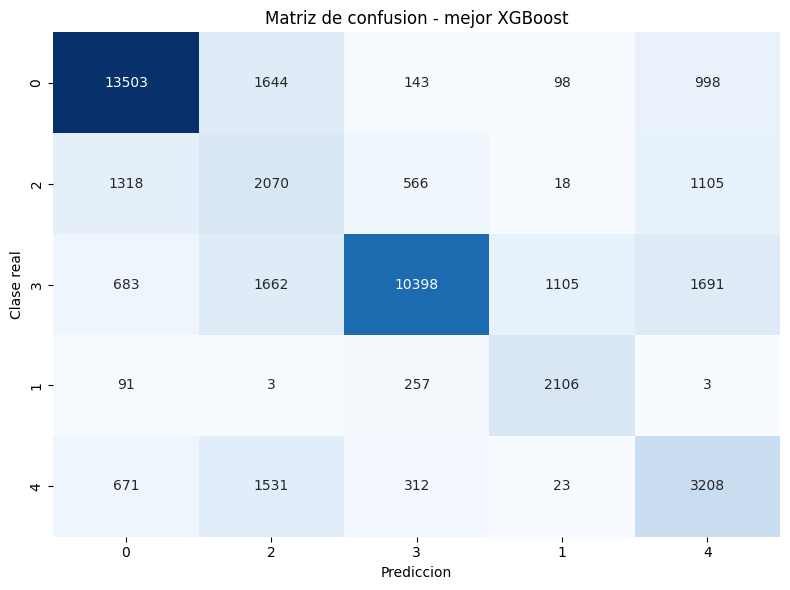

In [ ]:
# Visualice la matriz de confusion despues de entrenar y predecir
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusion - mejor XGBoost")
plt.xlabel("Prediccion")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

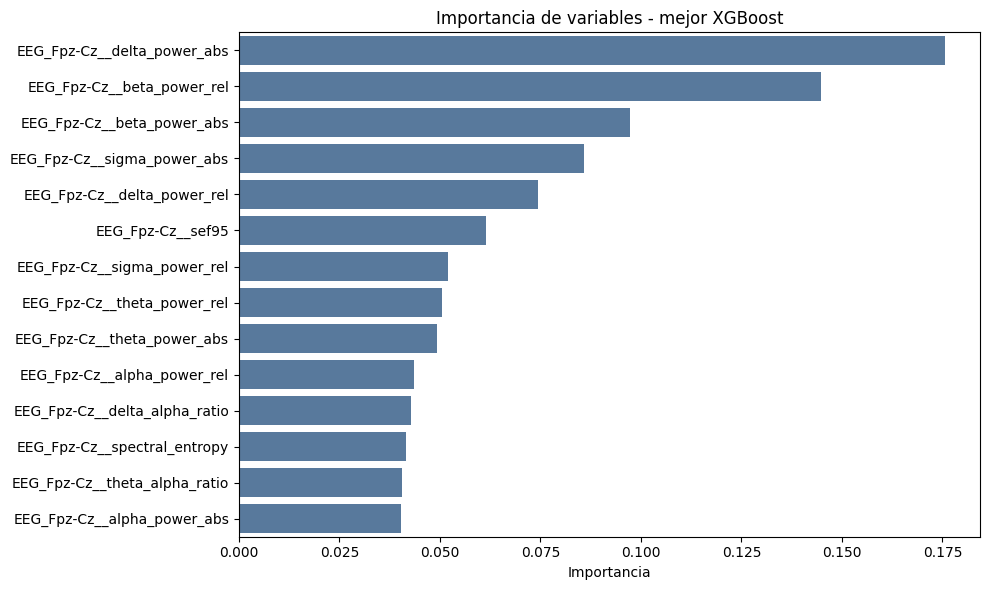

,feature,importance
0,EEG_Fpz-Cz__delta_power_abs,0.175572
9,EEG_Fpz-Cz__beta_power_rel,0.144819
8,EEG_Fpz-Cz__beta_power_abs,0.097223
6,EEG_Fpz-Cz__sigma_power_abs,0.085958
1,EEG_Fpz-Cz__delta_power_rel,0.074420
12,EEG_Fpz-Cz__sef95,0.061416
7,EEG_Fpz-Cz__sigma_power_rel,0.051972
3,EEG_Fpz-Cz__theta_power_rel,0.050591
2,EEG_Fpz-Cz__theta_power_abs,0.049342
5,EEG_Fpz-Cz__alpha_power_rel,0.043523


In [ ]:
# Visualice la importancia de variables despues del entrenamiento
feature_importance = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance": xgb_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x="importance", y="feature", color="#4C78A8")
plt.title("Importancia de variables - mejor XGBoost")
plt.xlabel("Importancia")
plt.ylabel("")
plt.tight_layout()
plt.show()

display(feature_importance)